# Where should a CPG's parameters start?

Last full run: 2026-10-23, 3 min 41 s, AMD Ryzen 7 5800, 16 workers (26 min
57 s serially on 2026-10-22, with the same results).

The trials run in a pool of worker processes (`ariel.simulation.process_pool`,
`WORKERS` of them, one per logical CPU by default): the (d) searches advance
together one CMA-ES generation per round (`gecko_trials.lockstep`) and the
draws of part 1 are all scored in one `pool.map`. Every random draw is still
made here, in the order of a serial run, so the numbers are those of a
serial run.

A search for a gait starts from random parameters. Does the distribution
they are drawn from decide whether the gecko walks? This notebook compares
four ways to draw the parameters of each of ARIEL's seven CPGs, on the
DSS-M15 hinges, with no search: 100 random draws per scheme per CPG,
each run for 10 s on the gecko in `SimpleFlatWorld`, as in
`cpg_locomotion`.

* (a) Current ranges: each model's `PARAMETER_RANGES`, uniform. For
  example `w` from 0 to 4 pi rad/s (0 to 2 Hz) and amplitudes from 0 to
  pi/2.
* (b) Narrow, hand-picked: frequencies from 0.5 to 1.5 Hz and amplitudes
  up to pi/4 (plus or minus pi/4 for the Tegotae models); the other groups
  as in (a).
* (c) What the servo can follow: as (a), but each amplitude is scaled to
  the largest one the DSS-M15 can follow at that joint's frequency. A joint
  at phase speed `w` and amplitude `A` needs a peak speed of `A w`, which
  must stay under the servo's %.2f rad/s at 6 V (`ServoSettings`); at
  2 Hz that caps the amplitude at 0.46 rad.
* (d) Searched distributions, the idea of the old `cpg.ipynb`: each group is
  drawn from a scaled beta distribution, shape `a`, `b` and range `c` to `d`
  as shares of the group's current range, and CMA-ES searches those four
  numbers per group, scoring each candidate by the mean distance of
  4 draws from it (50 candidates per CPG). Scheme (d)
  is tuned on the measure it is then scored on, from fresh draws: it shows
  how good a distribution can get, not a fair start.

A draw "walks" when it moves the core at least 0.25 m in 10 s, about a tenth
of the best gait `cpg_locomotion` found (2.44 m). The plan said 0.05 m, but
on the DSS-M15 hinges almost every random draw moves that far. The
distributions (d) found are saved to `__data__/cpg_initialisation/` and
copied into `cpg_initialisation_search`, which runs the searches (part 2).
Every finished piece appends a line to `__data__/cpg_initialisation/
progress.log`, so a run can be followed while it goes.

The notebook is marked slow (about 26 minutes serially, about 4 with 16
workers); `tools/run_notebooks.py`
runs it only with `--slow` or when named.

In [1]:
# Run time: the last code cell prints how long the whole notebook took
import sys
import time

sys.stdout.write(f"Started {time.strftime('%Y-%m-%d %H:%M:%S %Z')}\n")
NOTEBOOK_STARTED = time.perf_counter()

Started 2026-10-23 16:59:24 UTC


In [2]:
# Standard library
import json
import os
import time

# Third-party libraries
import astropy.units as u
import matplotlib.pyplot as plt
import nevergrad as ng
import numpy as np
from rich.console import Console

# Local libraries
from ariel import DATA
from ariel.parameters import DSSM15, FrozenModel, ServoSettings
from ariel.simulation import (
    AdaptiveHopfCPG,
    HopfCPG,
    LearnableTegotaeCPG,
    NaCPG,
    PhaseCPG,
    SwingStanceCPG,
    TegotaeCPG,
    process_pool,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 50  # keeps the notebook under 500 KB
console = Console()

MODELS = [
    HopfCPG,
    AdaptiveHopfCPG,
    PhaseCPG,
    SwingStanceCPG,
    NaCPG,
    TegotaeCPG,
    LearnableTegotaeCPG,
]
SCHEMES = ["a", "b", "c", "d"]
SECONDS = 10.0
STEPS_PER_CONTROL = 4
WALKS = 0.25  # metres in 10 s: a draw that moves at least this far "walks"
# The DSS-M15's speed at 6 V, the fastest a joint can follow
TOP_SPEED = ServoSettings().rating(DSSM15()).speed.to_value(u.rad / u.s)

DRAWS = 100
META_BUDGET = 50
META_DRAWS = 4
WORKERS = os.cpu_count()  # pool processes; 1 runs every trial in turn

In [3]:
# The trials live in gecko_trials.py, beside this notebook: a pool worker can
# import a function from a file, never from a notebook cell
from gecko_trials import Walk, lockstep, walk, walker

## The trial

The same 10 s trial as `cpg_locomotion`, with the same sensory inputs:
`Gecko.walk` from `gecko_trials.py` beside this notebook, which the pool's
worker processes import. The notebook keeps its own copy for the checks.

In [4]:
gecko = walker()
model = gecko.model
adjacency = gecko.adjacency


def trial(cpg):
    """Run one 10 s trial, as cpg_locomotion does (``Gecko.walk``).

    Returns
    -------
    float
        The distance the core travelled in the floor plane, in metres.
    """
    return gecko.walk(cpg, SECONDS)


def score(cpg_class, params):
    """Run one trial with the given flat parameters.

    Returns
    -------
    float
        The distance walked in 10 s, in metres.
    """
    cpg = cpg_class(adjacency)
    cpg.set_flat_params(np.asarray(params, dtype=np.float64))
    return trial(cpg)


def job(cpg_class, params):
    """Describe the trial ``score(cpg_class, params)`` runs, for the pool.

    Returns
    -------
    Walk
        The job ``gecko_trials.walk`` scores in a worker.
    """
    return Walk(cpg=cpg_class.__name__, params=np.asarray(params).tolist())


OUTPUT = DATA / "cpg_initialisation"
OUTPUT.mkdir(parents=True, exist_ok=True)
PROGRESS = OUTPUT / "progress.log"


def report(line):
    """Print a line and append it to the progress log.

    The log lets a run be followed from outside while the notebook runs:
    jupyter writes the outputs only at the end.
    """
    console.print(line)
    with PROGRESS.open("a", encoding="utf-8") as log:
        log.write(f"{time.strftime('%H:%M:%S')} {line}\n")


console.print(
    f"{model.nu} actuators, timestep {model.opt.timestep * 1000:.2f} ms,"
    f" servo top speed {TOP_SPEED:.3f} rad/s"
)

8 actuators, timestep 3.75 ms, servo top speed 5.818 rad/s

In [5]:
# Checks: the trial is deterministic: the same parameters walk the
# same distance twice
SAME = 1e-6  # metres
params = HopfCPG(adjacency, seed=3).get_flat_params().numpy()
assert abs(score(HopfCPG, params) - score(HopfCPG, params)) < SAME

## The schemes

Every scheme maps a point of the unit cube to parameters; scheme (d) also
draws that point from its beta distributions instead of uniformly.

In [6]:
class Shape(FrozenModel):
    """A scaled beta distribution for one parameter group (scheme d).

    Values are ``lower + (c + (d - c) * Beta(a, b)) * (upper - lower)``,
    with ``lower`` and ``upper`` the group's current range.
    """

    a: float
    b: float
    c: float
    d: float


UNIFORM = Shape(a=1.0, b=1.0, c=0.0, d=1.0)  # scheme d's start: scheme a


def slices(cpg):
    """Return the flat slice of every parameter group.

    Returns
    -------
    dict[str, slice]
        Group name to its slice of ``get_flat_params``.
    """
    out, start = {}, 0
    for name, size in cpg.group_sizes.items():
        out[name] = slice(start, start + size)
        start += size
    return out


def full_box(cpg):
    """Return the current ranges, the bounds every scheme lives in.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Lower and upper bound of every flat parameter.
    """
    lower, upper = cpg.parameter_bounds()
    return lower.numpy().astype(np.float64), upper.numpy().astype(np.float64)


def box(cpg, scheme, shapes):
    """Return the bounds of a scheme before scheme c's speed cap.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Lower and upper bound of every flat parameter.
    """
    lower, upper = full_box(cpg)
    for name, part in slices(cpg).items():
        if scheme == "b" and name.startswith("w"):
            lower[part], upper[part] = np.pi, 3 * np.pi  # 0.5 to 1.5 Hz
        elif scheme == "b" and name == "amplitudes":
            lower[part] = np.where(lower[part] < 0, -np.pi / 4, 0.0)
            upper[part] = np.pi / 4
        elif scheme == "d":
            shape = shapes.get(name, UNIFORM)
            low, high = lower[part].copy(), upper[part].copy()
            lower[part] = low + shape.c * (high - low)
            upper[part] = low + shape.d * (high - low)
    return lower, upper


def peak_rate(cpg, params):
    """Return each oscillator's fastest phase speed, in rad/s.

    Coupling and feedback are left out. A joint's peak speed is its
    amplitude times this rate.

    Returns
    -------
    np.ndarray
        One rate per joint.
    """
    part = slices(cpg)
    if isinstance(cpg, SwingStanceCPG):
        rate = np.maximum(params[part["w_swing"]], params[part["w_stance"]])
    else:
        rate = params[part["w"]].copy()
    if isinstance(cpg, NaCPG):  # the fast half turns at w / (1 - ha)
        rate /= 1 - np.abs(params[part["ha"]])
    return np.abs(rate)


def to_params(cpg, scheme, unit, shapes):
    """Map a point of the unit cube to parameters under a scheme.

    Scheme c scales each amplitude to the largest one the servo can follow
    at that joint's frequency: ``|A| * rate <= TOP_SPEED``.

    Returns
    -------
    np.ndarray
        The flat parameters.
    """
    lower, upper = box(cpg, scheme, shapes)
    params = lower + unit * (upper - lower)
    if scheme == "c":
        part = slices(cpg)["amplitudes"]
        rate = np.maximum(peak_rate(cpg, params), 1e-9)
        cap = np.minimum(upper[part], TOP_SPEED / rate)
        low = np.where(lower[part] < 0, -cap, 0.0)
        params[part] = low + unit[part] * (cap - low)
    return params


def draw_unit(cpg, scheme, rng, shapes):
    """Draw a point of the unit cube from a scheme's distribution.

    Returns
    -------
    np.ndarray
        Uniform for schemes a to c, beta per group for scheme d.
    """
    unit = rng.uniform(size=cpg.num_of_parameters)
    if scheme == "d":
        for name, part in slices(cpg).items():
            shape = shapes.get(name, UNIFORM)
            unit[part] = rng.beta(shape.a, shape.b, size=part.stop - part.start)
    return unit


def draw(cpg, scheme, rng, shapes):
    """Draw starting parameters from a scheme.

    Returns
    -------
    np.ndarray
        The flat parameters.
    """
    return to_params(cpg, scheme, draw_unit(cpg, scheme, rng, shapes), shapes)

In [7]:
# Checks: every scheme keeps its draws inside its own ranges and the
# current ones, and scheme (c)'s amplitudes within the servo's speed;
# scheme (d) is checked with one test distribution on every group
TEST_SHAPE = Shape(a=2.0, b=3.0, c=0.2, d=0.6)
check_rng = np.random.default_rng(7)
for cpg_class in MODELS:
    name = cpg_class.__name__
    cpg = cpg_class(adjacency)
    full_lower, full_upper = full_box(cpg)
    test_shapes = dict.fromkeys(cpg.parameter_groups, TEST_SHAPE)
    for scheme in SCHEMES:
        shapes = test_shapes if scheme == "d" else {}
        lower, upper = box(cpg, scheme, shapes)
        for _ in range(20):
            params = draw(cpg, scheme, check_rng, shapes)
            assert (params >= full_lower - SAME).all(), (name, scheme)
            assert (params <= full_upper + SAME).all(), (name, scheme)
            assert (params >= lower - SAME).all(), (name, scheme)
            assert (params <= upper + SAME).all(), (name, scheme)
            if scheme == "c":
                amplitude = np.abs(params[slices(cpg)["amplitudes"]])
                assert (
                    amplitude * peak_rate(cpg, params) <= TOP_SPEED + SAME
                ).all()

## Scheme (d): searching the distributions

For each CPG and each parameter group, CMA-ES searches `a` and `b` (0.2 to
5) and `c` and `d` (0 to 1, sorted, at least 0.02 apart), starting from the
uniform distribution, which is scheme (a).

In [8]:
def shapes_of(values, names):
    """Turn a flat search vector into one Shape per group.

    Returns
    -------
    dict[str, Shape]
        Group name to its distribution.
    """
    out = {}
    for row, name in zip(values.reshape(len(names), 4), names, strict=True):
        low, high = sorted(row[2:])
        high = max(high, low + 0.02)
        if high > 1:
            low, high = 0.98, 1.0
        out[name] = Shape(a=row[0], b=row[1], c=low, d=high)
    return out


def start_search(cpg_class, seed=0):
    """Set up the search of one CPG's distributions.

    Returns
    -------
    tuple[ng.optimizers.base.Optimizer, CPG, list[str], np.random.Generator]
        CMA-ES over a, b, c and d of every group, a CPG to draw for, the
        group names, and the generator that draws the parameters.
    """
    cpg = cpg_class(adjacency)
    names = list(cpg.parameter_groups)
    lower = np.tile([0.2, 0.2, 0.0, 0.0], len(names))
    upper = np.tile([5.0, 5.0, 1.0, 1.0], len(names))
    parametrization = ng.p.Array(
        shape=(4 * len(names),), lower=lower, upper=upper
    )
    parametrization.value = np.tile([1.0, 1.0, 0.0, 1.0], len(names))
    parametrization.random_state = np.random.RandomState(seed)
    optimizer = ng.optimizers.CMA(
        parametrization=parametrization, budget=META_BUDGET
    )
    return optimizer, cpg, names, np.random.default_rng(seed)


searches = {cpg_class.__name__: start_search(cpg_class) for cpg_class in MODELS}


def evaluate(asked):
    """Score one round of candidate distributions in the pool.

    Each candidate's META_DRAWS parameter sets are drawn here, in the order
    a serial run draws them, then all trials of the round run at once.

    Returns
    -------
    list[float]
        Minus each candidate's mean distance, since CMA-ES minimises.
    """
    jobs = []
    for name, _, candidate in asked:
        _, cpg, names, rng = searches[name]
        shapes = shapes_of(candidate.value, names)
        jobs += [
            job(type(cpg), draw(cpg, "d", rng, shapes))
            for _ in range(META_DRAWS)
        ]
    walked = list(pool.map(walk, jobs))
    report(f"(d) search: scored {len(asked)} candidates")
    return [
        -float(np.mean(walked[k * META_DRAWS : (k + 1) * META_DRAWS]))
        for k in range(len(asked))
    ]


PROGRESS.write_text("", encoding="utf-8")
report(f"part 1 started: {len(MODELS)} CPGs, {DRAWS} draws per scheme")
started = time.perf_counter()
with process_pool(WORKERS) as pool:
    told = lockstep(
        {name: optimizer for name, (optimizer, _, _, _) in searches.items()},
        META_BUDGET,
        evaluate,
    )
found = {}
meta_scores = {}
for name, (_, _, names, _) in searches.items():
    meta_scores[name] = [-value for _, value in told[name]]
    first_best = int(np.argmax(meta_scores[name]))
    found[name] = shapes_of(told[name][first_best][0].value, names)
    report(
        f"DONE (d) search {name}: best candidate"
        f" {max(meta_scores[name]):.3f} m mean of"
        f" {META_DRAWS} draws, uniform start {meta_scores[name][0]:.3f} m"
    )
report(
    f"DONE (d) searches: {len(MODELS) * META_BUDGET * META_DRAWS} trials in"
    f" {time.perf_counter() - started:.0f} s on {WORKERS} workers"
)

part 1 started: 7 CPGs, 100 draws per scheme

(d) search: scored 43 candidates

(d) search: scored 43 candidates

(d) search: scored 43 candidates

(d) search: scored 43 candidates

...

DONE (d) search SwingStanceCPG: best candidate 0.397 m mean of 4 draws, uniform start 0.237 m

DONE (d) search NaCPG: best candidate 0.669 m mean of 4 draws, uniform start 0.211 m

DONE (d) search TegotaeCPG: best candidate 0.376 m mean of 4 draws, uniform start 0.217 m

DONE (d) search LearnableTegotaeCPG: best candidate 0.414 m mean of 4 draws, uniform start 0.330 m

DONE (d) searches: 1400 trials in 76 s on 16 workers

In [9]:
# Checks: every CPG's search scored its whole budget and found a
# distribution for every group, with 0 <= c < d <= 1
for cpg_class in MODELS:
    name = cpg_class.__name__
    assert len(meta_scores[name]) == META_BUDGET, name
    assert np.isfinite(meta_scores[name]).all(), name
    groups = set(cpg_class(adjacency).parameter_groups)
    assert set(found[name]) == groups, name
    for shape in found[name].values():
        assert 0 <= shape.c < shape.d <= 1, name

## The distributions scheme (d) found

The beta density of the frequency and amplitude groups of each CPG, over the
group's current range; the flat grey line is scheme (a).

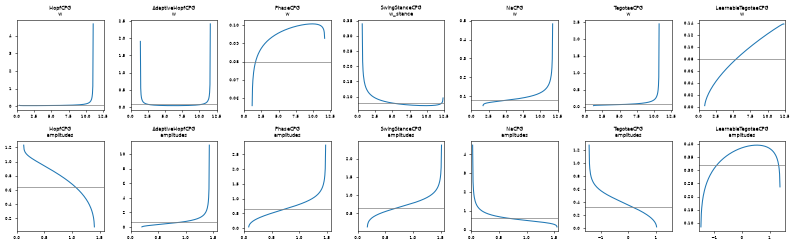

saved 
/home/jmdm/projects/ariel/.claude/worktrees/sweet-haslett-17636a/tests/functional/simulation/__data__/cpg_initialis
ation/distributions.json

In [10]:
fig, axes = plt.subplots(2, len(MODELS), figsize=(16, 5))
grid = np.linspace(0.001, 0.999, 200)
for column, cpg_class in enumerate(MODELS):
    shapes = found[cpg_class.__name__]
    frequency = "w_stance" if cpg_class is SwingStanceCPG else "w"
    for row, name in enumerate([frequency, "amplitudes"]):
        ax = axes[row, column]
        shape = shapes[name]
        lower, upper = (
            cpg_class.PARAMETER_RANGES[name].c,
            cpg_class.PARAMETER_RANGES[name].d,
        )
        x = lower + (shape.c + (shape.d - shape.c) * grid) * (upper - lower)
        density = grid ** (shape.a - 1) * (1 - grid) ** (shape.b - 1)
        density /= density.mean() * (shape.d - shape.c) * (upper - lower)
        ax.plot(x, density)
        ax.axhline(1 / (upper - lower), color="grey", linewidth=1)
        ax.set_xlim(lower, upper)
        ax.set_title(f"{cpg_class.__name__}\n{name}", fontsize=7)
        ax.tick_params(labelsize=6)
fig.tight_layout()
plt.show()


class Found(FrozenModel):
    """The distributions scheme (d) found for one CPG."""

    cpg: str
    shapes: dict[str, Shape]
    best: float


(OUTPUT / "distributions.json").write_text(
    json.dumps(
        {
            name: Found(
                cpg=name, shapes=shapes, best=max(meta_scores[name])
            ).model_dump()
            for name, shapes in found.items()
        },
        indent=2,
    ),
    encoding="utf-8",
)
console.print(f"saved {OUTPUT / 'distributions.json'}")

In [11]:
# Checks: the saved file holds every CPG's distributions as found
saved = json.loads((OUTPUT / "distributions.json").read_text("utf-8"))
assert set(saved) == set(found)
for name, entry in saved.items():
    assert Found.model_validate(entry).shapes == found[name], name

## Part 1: random draws, no search

Each scheme draws the same number of parameter sets per CPG, from its own
seeded generator, and runs each once.

In [12]:
jobs, keys = [], []
for cpg_class in MODELS:
    name = cpg_class.__name__
    cpg = cpg_class(adjacency)
    for index, scheme in enumerate(SCHEMES):
        rng = np.random.default_rng(100 + index)
        shapes = found[name] if scheme == "d" else {}
        for _ in range(DRAWS):
            jobs.append(job(cpg_class, draw(cpg, scheme, rng, shapes)))
            keys.append((name, scheme))

started = time.perf_counter()
with process_pool(WORKERS) as pool:
    walked = list(pool.map(walk, jobs))
distances = {
    key: np.array([d for k, d in zip(keys, walked, strict=True) if k == key])
    for key in dict.fromkeys(keys)
}
for cpg_class in MODELS:
    name = cpg_class.__name__
    summary = ", ".join(
        f"({scheme}) median {np.median(distances[name, scheme]):.3f} m,"
        f" walks {np.mean(distances[name, scheme] >= WALKS):.0%}"
        for scheme in SCHEMES
    )
    report(f"DONE draws {name}: {summary}")
report(
    f"DONE draws: {len(jobs)} trials in {time.perf_counter() - started:.0f} s"
    f" on {WORKERS} workers"
)

DONE draws HopfCPG: (a) median 0.369 m, walks 64%, (b) median 0.297 m, walks 52%, (c) median 0.240 m, walks 48%, 
(d) median 0.470 m, walks 76%

DONE draws AdaptiveHopfCPG: (a) median 0.356 m, walks 68%, (b) median 0.284 m, walks 54%, (c) median 0.253 m, walks
52%, (d) median 0.375 m, walks 68%

DONE draws PhaseCPG: (a) median 0.322 m, walks 63%, (b) median 0.209 m, walks 44%, (c) median 0.147 m, walks 33%, 
(d) median 0.457 m, walks 69%

DONE draws SwingStanceCPG: (a) median 0.159 m, walks 29%, (b) median 0.173 m, walks 34%, (c) median 0.101 m, walks 
7%, (d) median 0.177 m, walks 31%

DONE draws NaCPG: (a) median 0.305 m, walks 60%, (b) median 0.334 m, walks 62%, (c) median 0.195 m, walks 37%, (d) 
median 0.301 m, walks 58%

DONE draws TegotaeCPG: (a) median 0.110 m, walks 20%, (b) median 0.079 m, walks 6%, (c) median 0.080 m, walks 7%, 
(d) median 0.134 m, walks 26%

DONE draws LearnableTegotaeCPG: (a) median 0.125 m, walks 11%, (b) median 0.092 m, walks 5%, (c) median 0.112 m, 
walks 5%, (d) median 0.132 m, walks 19%

DONE draws: 2800 trials in 139 s on 16 workers

In [13]:
# Checks: every scheme drew DRAWS sets per CPG, each with a finite
# distance
assert len(distances) == len(MODELS) * len(SCHEMES)
for (name, scheme), values in distances.items():
    assert len(values) == DRAWS, (name, scheme)
    assert np.isfinite(values).all(), (name, scheme)

## Results

The distance of every draw, per CPG and scheme (box: quartiles and median,
whiskers: 5 to 95 %, dots: the rest), and the share of draws that walk.

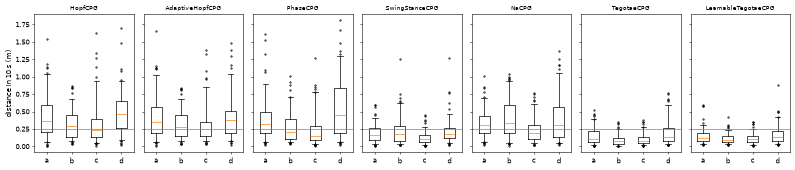

CPG                   (a) median  walks   best  (b) median  walks   best  (c) median  walks   best  (d) median  
walks   best

HopfCPG                    0.369    64%  1.547       0.297    52%  0.872       0.240    48%  1.630       0.470    
76%  1.699

AdaptiveHopfCPG            0.356    68%  1.656       0.284    54%  0.834       0.253    52%  1.378       0.375    
68%  1.485

PhaseCPG                   0.322    63%  1.606       0.209    44%  1.008       0.147    33%  1.274       0.457    
69%  1.807

SwingStanceCPG             0.159    29%  0.600       0.173    34%  1.250       0.101     7%  0.448       0.177    
31%  1.273

NaCPG                      0.305    60%  1.010       0.334    62%  1.042       0.195    37%  0.765       0.301    
58%  1.365

TegotaeCPG                 0.110    20%  0.529       0.079     6%  0.346       0.080     7%  0.383       0.134    
26%  0.767

LearnableTegotaeCPG        0.125    11%  0.589       0.092     5%  0.416       0.112     5%  0.351       0.132    
19%  0.881

In [14]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(16, 3.5), sharey=True)
for ax, cpg_class in zip(axes, MODELS, strict=True):
    name = cpg_class.__name__
    ax.boxplot(
        [distances[name, scheme] for scheme in SCHEMES],
        tick_labels=SCHEMES,
        whis=(5, 95),
        flierprops={"markersize": 2},
    )
    ax.axhline(WALKS, color="grey", linewidth=1)
    ax.set_title(name, fontsize=8)
axes[0].set_ylabel("distance in 10 s (m)")
fig.tight_layout()
plt.show()

console.print(
    f"{'CPG':20s}" + "".join(f"  ({s}) median  walks   best" for s in SCHEMES)
)
for cpg_class in MODELS:
    name = cpg_class.__name__
    console.print(
        f"{name:20s}"
        + "".join(
            f"  {np.median(distances[name, s]):10.3f}"
            f" {np.mean(distances[name, s] >= WALKS):6.0%}"
            f" {distances[name, s].max():6.3f}"
            for s in SCHEMES
        )
    )

In [15]:
# Checks: for every CPG some scheme has a draw that walks
for cpg_class in MODELS:
    name = cpg_class.__name__
    best = max(distances[name, scheme].max() for scheme in SCHEMES)
    assert best >= WALKS, name

# Run time of the whole notebook; after a full run, copy it into the
# "Last full run" line under the title
minutes, seconds = divmod(round(time.perf_counter() - NOTEBOOK_STARTED), 60)
report(f"Total run time: {minutes} min {seconds} s")

Total run time: 3 min 41 s

## Conclusions

From the run of 2026-10-23 on the DSS-M15 hinges (100 draws per scheme per
CPG; numbers from the table above). Every draw comes from a seeded
generator, so a rerun gives the same numbers: the 16-worker run of
2026-10-23 printed exactly those of the serial run of 2026-10-22. A change
of seeds would move them; the ranking is what to check then.

1. The current ranges (a) are a good default. Hand-picking "sensible" ranges
   (b) makes random gaits walk less often and less far for five of seven
   CPGs: `PhaseCPG` has a median of 0.32 m and 63 % walking with (a), 0.21 m
   and 44 % with (b). Only `SwingStanceCPG` and `NaCPG` gain from (b), and
   by little (0.16 to 0.17 m, 0.31 to 0.33 m).
2. Keeping every amplitude within what the servo can follow (c) costs the
   most: it is the worst or close to the worst scheme for all seven CPGs
   (`SwingStanceCPG` walks in 7 % of draws, against 29 % with (a); `PhaseCPG`
   in 33 %). A guess at why, not measured here: a random gait moves the body
   mainly by asking for swings larger than the servo delivers, and the
   saturated motion still pushes, while a gait the servo can follow exactly
   swings too little to walk.
3. The searched distributions (d) are the best start for five CPGs and tie
   with (a) for `AdaptiveHopfCPG` and `NaCPG`: `HopfCPG` 0.47 against 0.37 m
   (76 % against 64 % walking), `PhaseCPG` 0.46 against 0.32 m. But fresh
   draws walk much less than the search reported (`HopfCPG` 0.87 m in the
   search, 0.47 m median here; `NaCPG` 0.67 against 0.30 m): scoring each
   candidate distribution on 4 draws picks the luckiest candidate, not the
   best. More draws per candidate would make scheme (d) honest and slower.
4. Single lucky draws already walk far: the best of 100 draws from (d)
   reaches 1.70 m for `HopfCPG` and 1.81 m for `PhaseCPG`, against 1.60 and
   2.44 m that `cpg_locomotion`'s searches of 450 trials found.
5. `SwingStanceCPG` and the two Tegotae models rarely walk from any random
   start (5 to 34 % of draws), so they depend on the search far more than
   the others.

Whether the start still matters after a search is the question of
`cpg_initialisation_search`.